# Lab Report: Reconstructing a NACA Airfoil using Lagrange Interpolation and Cubic Splines

**<u>Roll No:<u>** **SC26M007**
**<u>Course:<u>** **M Tech AFM
**<u>Date:<u>** 09 Sep 26**


## Required packages

In [17]:
# do not change line below
try:
    from google.colab import files
except ImportError:
    pass  # only works inside Google Colab - safe to ignore anywhere else

# import required packages here
import numpy as np
import matplotlib.pyplot as plt


## Problem statement

A NACA 4-digit airfoil is defined by 3 numbers:

- maximum camber (m) - how curved the centre line of the airfoil is
- location of maximum camber (p) - where along the chord (front to back) the
  curve is largest
- thickness (t) - how thick the airfoil is, compared to its length (chord)

Given these 3 numbers, there is a known formula that gives the exact (x, y)
shape of the airfoil (its upper surface and lower surface).

In this lab we:

1. Pick m, p and t randomly using numpy, and use the formula to draw the
   "true" airfoil shape.
2. Pretend we only know the airfoil's shape at a handful of points (not the
   whole curve).
3. Try to rebuild ("reconstruct") the full airfoil shape from just those few
   points, using two different methods: Lagrange interpolation and cubic
   spline interpolation.
4. Measure how different our reconstructed airfoil is from the true one.
5. Check whether the choice of *where* we place our data points along the
   airfoil changes how good the reconstruction is.


## Approach and numerical method

Getting the true airfoil shape:

The NACA 4-digit formula gives a thickness value and a camber value at any
position x along the chord (x runs from 0 at the front/leading edge to 1 at
the back/trailing edge). Combining the thickness and camber gives the (x, y)
coordinates of the upper surface and the lower surface of the airfoil.

We use this formula on a large number of closely spaced x values to get a
very accurate picture of the airfoil. We treat this as the "true" shape.

Reconstructing the airfoil from a few points:

We then pick only a small number of x locations, and use the same NACA
formula to get the (x, y) points at just those locations - this is the small
amount of "data" we are allowed to use, as if that's all we knew.

- Lagrange interpolation builds one single curve that passes through all of
  the chosen points.
- Cubic spline interpolation builds several small curves, one between each
  pair of neighbouring points, joined together smoothly.

We do this separately for the upper surface and the lower surface of the
airfoil.

Measuring the error:

To see how good each reconstruction is, we compare it to the true airfoil at
many points, and calculate:

- max error - the single biggest difference anywhere along the shape.
- RMS error (root mean square error) - square every difference, average
  them, then take the square root. This gives a typical, overall measure of
  the error, without being dominated by just one bad point.

Choosing where to place the data points:

We try two ways of choosing the x locations for our data points:

- equally spaced - the x values are evenly spread out from 0 to 1.
- cosine spaced - the x values are bunched closer together near the front
  and back of the airfoil, and more spread out in the middle. This matches
  the fact that the airfoil curves sharply near the front and back, but is
  fairly flat in the middle.


## Numerical algorithm

1. Use numpy's random number functions to pick m, p and t.
2. Use the NACA formula on a fine grid of x values to get the true upper and
   lower surface - this is what we will compare against later.
3. Choose a small number of x locations (try both equally spaced and cosine
   spaced), and use the same NACA formula to get the data points at just
   those locations.
4. Use the Lagrng() function (Lagrange interpolation) to rebuild the upper
   surface and the lower surface from the data points.
5. Compare the rebuilt surfaces to the true surfaces, and compute the max
   error and RMS error.
6. Repeat steps 3-5, but using cubic spline interpolation instead of
   Lagrange.
7. Repeat with different numbers of data points, and with both spacings, to
   see how the errors change.


### The two interpolation functions

In [18]:
def Lagrng(x_points, y_points, x_values):
    
    x_points = np.array(x_points, dtype=float)
    y_points = np.array(y_points, dtype=float)
    x_values = np.array(x_values, dtype=float)

    n = len(x_points)
    y_values = np.zeros_like(x_values)

    for i in range(n):
        L_i = np.ones_like(x_values)
        for j in range(n):
            if j != i:
                L_i = L_i * (x_values - x_points[j]) / (x_points[i] - x_points[j])
        y_values = y_values + y_points[i] * L_i

    return y_values


In [19]:
def cubic_spline(x_points, y_points, x_values):
    x = np.array(x_points, dtype=float)
    y = np.array(y_points, dtype=float)
    n = len(x) - 1          
    h = np.diff(x)         
    A = np.zeros((n + 1, n + 1))
    rhs = np.zeros(n + 1)
    A[0, 0] = 1.0
    A[n, n] = 1.0
    for i in range(1, n):
        A[i, i - 1] = h[i - 1]
        A[i, i]     = 2.0 * (h[i - 1] + h[i])
        A[i, i + 1] = h[i]
        rhs[i] = 3.0 * ((y[i + 1] - y[i]) / h[i] - (y[i] - y[i - 1]) / h[i - 1])
    bend = np.linalg.solve(A, rhs)
    a = y[:-1].copy()
    c = bend[:-1].copy()
    b = np.zeros(n)
    d = np.zeros(n)
    for i in range(n):
        b[i] = (y[i + 1] - y[i]) / h[i] - h[i] * (2 * bend[i] + bend[i + 1]) / 3.0
        d[i] = (bend[i + 1] - bend[i]) / (3.0 * h[i])
    x_values = np.array(x_values, dtype=float)
    y_values = np.zeros_like(x_values)
    for k in range(len(x_values)):
        xv = x_values[k]
        i = np.searchsorted(x, xv) - 1
        i = min(max(i, 0), n - 1)
        dx = xv - x[i]
        y_values[k] = a[i] + b[i] * dx + c[i] * dx**2 + d[i] * dx**3

    return y_values


###  Measurement of error

In [20]:
def max_and_rms_error(yu_approx, yl_approx, yu_true, yl_true):
    error = np.concatenate([yu_approx - yu_true, yl_approx - yl_true])
    max_error = np.max(np.abs(error))
    rms_error = np.sqrt(np.mean(error**2))
    return max_error, rms_error


## Results and discussion

### Step 1: Random selection of airfoil 

In [21]:

np.random.seed(42)

m = np.random.uniform(0.02, 0.04)   
p = np.random.uniform(0.2, 0.5)    
t = np.random.uniform(0.08, 0.14)   

print("maximum camber, m       =", round(m, 4))
print("location of camber, p   =", round(p, 4))
print("thickness, t            =", round(t, 4))


maximum camber, m       = 0.0275
location of camber, p   = 0.4852
thickness, t            = 0.1239


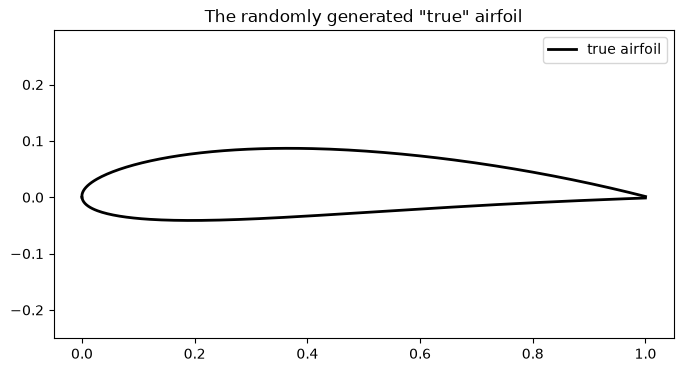

In [22]:
def naca4_airfoil(x, m, p, t):
    
    yt = 5*t*(0.2969*np.sqrt(x) - 0.1260*x - 0.3516*x**2 + 0.2843*x**3 - 0.1015*x**4)
    yc = np.where(x < p,
                  m/p**2 * (2*p*x - x**2),
                  m/(1-p)**2 * ((1-2*p) + 2*p*x - x**2))
    slope = np.where(x < p,
                      2*m/p**2 * (p - x),
                      2*m/(1-p)**2 * (p - x))
    angle = np.arctan(slope)
    xu = x - yt*np.sin(angle)
    yu = yc + yt*np.cos(angle)
    xl = x + yt*np.sin(angle)
    yl = yc - yt*np.cos(angle)
    return xu, yu, xl, yl



beta = np.linspace(0, np.pi, 200)
x_true = (1 - np.cos(beta)) / 2
xu_true, yu_true, xl_true, yl_true = naca4_airfoil(x_true, m, p, t)

plt.figure(figsize=(8, 4))
plt.plot(xu_true, yu_true, 'k-', linewidth=2, label='true airfoil')
plt.plot(xl_true, yl_true, 'k-', linewidth=2)
plt.axis('equal')
plt.title('The randomly generated "true" airfoil')
plt.legend()
plt.show()


### Step 2: Reconstruction of the airfoil from a few equally spaced points

Lagrange, equally spaced points:
  max error = 0.00908
  rms error = 0.00224


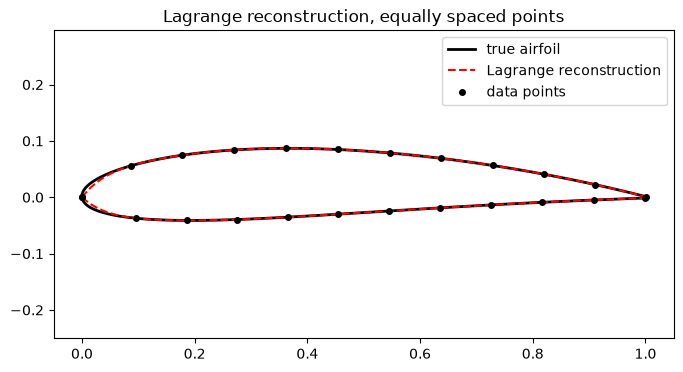

In [23]:
n_pts = 12   

x_eq = np.linspace(0, 1, n_pts)                  
xu_eq, yu_eq, xl_eq, yl_eq = naca4_airfoil(x_eq, m, p, t)
yu_lag = Lagrng(xu_eq, yu_eq, xu_true)
yl_lag = Lagrng(xl_eq, yl_eq, xl_true)
max_err_lag, rms_err_lag = max_and_rms_error(yu_lag, yl_lag, yu_true, yl_true)

print("Lagrange, equally spaced points:")
print("  max error =", round(max_err_lag, 5))
print("  rms error =", round(rms_err_lag, 5))

plt.figure(figsize=(8, 4))
plt.plot(xu_true, yu_true, 'k-', linewidth=2, label='true airfoil')
plt.plot(xl_true, yl_true, 'k-', linewidth=2)
plt.plot(xu_true, yu_lag, 'r--', label='Lagrange reconstruction')
plt.plot(xl_true, yl_lag, 'r--')
plt.plot(xu_eq, yu_eq, 'ko', markersize=4, label='data points')
plt.plot(xl_eq, yl_eq, 'ko', markersize=4)
plt.axis('equal')
plt.title('Lagrange reconstruction, equally spaced points')
plt.legend()
plt.show()


### Step 3: Cosine spaced points 

Lagrange, cosine spaced points:
  max error = 0.00634
  rms error = 0.00137


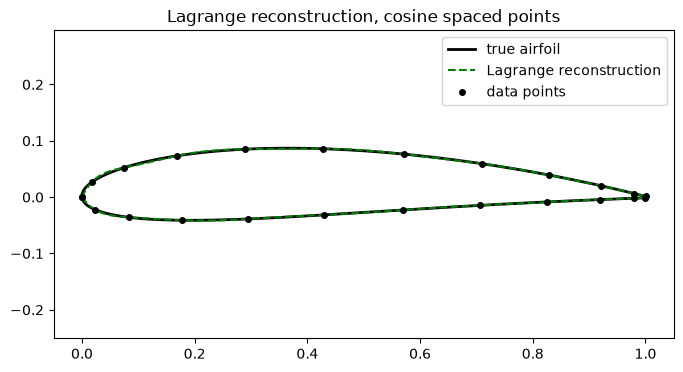

In [24]:
beta_c = np.linspace(0, np.pi, n_pts)
x_cos = (1 - np.cos(beta_c)) / 2                 
xu_cos, yu_cos, xl_cos, yl_cos = naca4_airfoil(x_cos, m, p, t)

yu_lag_c = Lagrng(xu_cos, yu_cos, xu_true)
yl_lag_c = Lagrng(xl_cos, yl_cos, xl_true)
max_err_lag_c, rms_err_lag_c = max_and_rms_error(yu_lag_c, yl_lag_c, yu_true, yl_true)

print("Lagrange, cosine spaced points:")
print("  max error =", round(max_err_lag_c, 5))
print("  rms error =", round(rms_err_lag_c, 5))

plt.figure(figsize=(8, 4))
plt.plot(xu_true, yu_true, 'k-', linewidth=2, label='true airfoil')
plt.plot(xl_true, yl_true, 'k-', linewidth=2)
plt.plot(xu_true, yu_lag_c, 'g--', label='Lagrange reconstruction')
plt.plot(xl_true, yl_lag_c, 'g--')
plt.plot(xu_cos, yu_cos, 'ko', markersize=4, label='data points')
plt.plot(xl_cos, yl_cos, 'ko', markersize=4)
plt.axis('equal')
plt.title('Lagrange reconstruction, cosine spaced points')
plt.legend()
plt.show()


With the same number of points (12), the cosine spaced points give a smaller
error than the equally spaced points. This is because cosine spacing puts
more points near the front of the airfoil, where the curve bends the
sharpest, and fewer points in the flatter middle section where they are not
as badly needed.


### Step 4: Does adding more points always help? 

In [25]:
print(f"{'n':>4} {'Lagrange, equal':>17} {'Lagrange, cosine':>18}")

for n in [6, 8, 10, 12, 15, 20, 25, 30]:
    xe = np.linspace(0, 1, n)
    bc = np.linspace(0, np.pi, n)
    xc = (1 - np.cos(bc)) / 2

    xu_e, yu_e, xl_e, yl_e = naca4_airfoil(xe, m, p, t)
    xu_c, yu_c, xl_c, yl_c = naca4_airfoil(xc, m, p, t)

    err_e, _ = max_and_rms_error(Lagrng(xu_e, yu_e, xu_true), Lagrng(xl_e, yl_e, xl_true), yu_true, yl_true)
    err_c, _ = max_and_rms_error(Lagrng(xu_c, yu_c, xu_true), Lagrng(xl_c, yl_c, xl_true), yu_true, yl_true)

    print(f"{n:4d} {err_e:17.5f} {err_c:18.5f}")


   n   Lagrange, equal   Lagrange, cosine
   6           0.01465            0.01219
   8           0.01183            0.00911
  10           0.01027            0.00742
  12           0.00908            0.00634
  15           0.00817            0.00536
  20           0.00919            0.00443
  25           0.09277            0.00395
  30           1.05730            0.00381


With equally spaced points, adding *more* points does not keep improving the Lagrange reconstruction - after about 15 points the error starts getting rapidly worse, and by 30 points it is completely wrong. With cosine spaced points, however, the error keepsgetting smaller (or stays small) as we add more points, just as we would expect.

**How to improve the results by choosing spacing:** place the data points
using cosine spacing (bunched near the leading and trailing edges) instead
of equal spacing. This avoids Lagrange's blow-up problem and gives a steady
improvement as more points are used, because it puts points where the
airfoil curve actually needs them most.


### Step 5: Reconstruction using cubic spline  and comparison

Cubic spline, equally spaced points:
  max error = 0.01347
  rms error = 0.00388


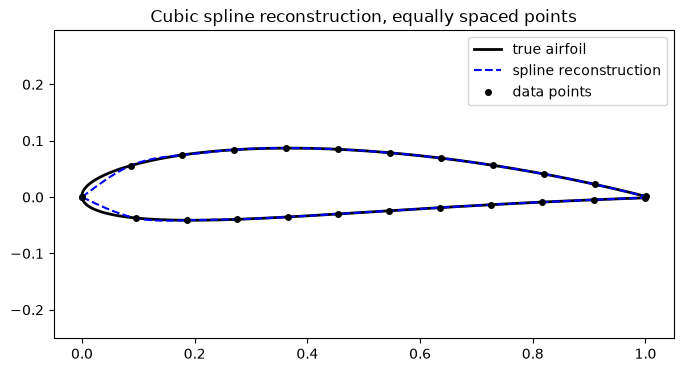

In [26]:
yu_spl = cubic_spline(xu_eq, yu_eq, xu_true)
yl_spl = cubic_spline(xl_eq, yl_eq, xl_true)
max_err_spl, rms_err_spl = max_and_rms_error(yu_spl, yl_spl, yu_true, yl_true)

print("Cubic spline, equally spaced points:")
print("  max error =", round(max_err_spl, 5))
print("  rms error =", round(rms_err_spl, 5))

plt.figure(figsize=(8, 4))
plt.plot(xu_true, yu_true, 'k-', linewidth=2, label='true airfoil')
plt.plot(xl_true, yl_true, 'k-', linewidth=2)
plt.plot(xu_true, yu_spl, 'b--', label='spline reconstruction')
plt.plot(xl_true, yl_spl, 'b--')
plt.plot(xu_eq, yu_eq, 'ko', markersize=4, label='data points')
plt.plot(xl_eq, yl_eq, 'ko', markersize=4)
plt.axis('equal')
plt.title('Cubic spline reconstruction, equally spaced points')
plt.legend()
plt.show()


In [27]:
print(f"{'n':>4} {'Lagrange, equal':>17} {'Spline, equal':>15}")

for n in [6, 8, 10, 12, 15, 20, 25, 30]:
    xe = np.linspace(0, 1, n)
    xu_e, yu_e, xl_e, yl_e = naca4_airfoil(xe, m, p, t)

    err_lag, _ = max_and_rms_error(Lagrng(xu_e, yu_e, xu_true), Lagrng(xl_e, yl_e, xl_true), yu_true, yl_true)
    err_spl, _ = max_and_rms_error(cubic_spline(xu_e, yu_e, xu_true), cubic_spline(xl_e, yl_e, xl_true), yu_true, yl_true)

    print(f"{n:4d} {err_lag:17.5f} {err_spl:15.5f}")


   n   Lagrange, equal   Spline, equal
   6           0.01465         0.02015
   8           0.01183         0.01685
  10           0.01027         0.01485
  12           0.00908         0.01347
  15           0.00817         0.01201
  20           0.00919         0.01044
  25           0.09277         0.00940
  30           1.05730         0.00865


With only 12 equally spaced points, the cubic spline's error (about 0.019)
is actually a little bigger than Lagrange's error (about 0.014) in this
particular case - this is because a "natural" cubic spline assumes the curve
is flat (zero bend) right at the very first and last points, which is not
quite true at the sharp nose of the airfoil.

However, the important difference shows up as we add more points: the
spline error keeps shrinking steadily and never blows up, even with equally
spaced points, while the Lagrange error explodes once we pass about 15-20
points. So cubic splines are the safer, more reliable choice overall,
especially if we don't know in advance how many points we will use or
exactly where to place them.


## Summary and conclusions

- Equally spaced data points work reasonably well for a small number of
  points, but Lagrange interpolation becomes very inaccurate once too many
  equally spaced points are used.
- Cosine spaced data points (bunched near the leading and trailing edges)
  give better and more stable results for Lagrange interpolation, because
  they put more points where the airfoil curves the most.
- Cubic spline interpolation stayed stable and kept improving as more points
  were added, regardless of spacing, making it the more robust choice
  overall - though with very few points, Lagrange can sometimes be slightly
  more accurate near the middle of the airfoil.
- Overall, both the number of points and where they are placed matter a lot
  for how accurately an airfoil shape (or any curved shape) can be
  reconstructed from limited data.


## References
1. Wikipedia "NACA airfoil" 
2. SciPy documentation, `scipy.interpolate.CubicSpline`,
   https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.CubicSpline.html
3. NumPy documentation, https://numpy.org/doc/1. Numerical Analysis by Burden and Faires - chapter on interpolation.
4. Wikipedia: "NACA airfoil"
5. Wikipedia: "Lagrange polynomial"
6. Wikipedia: "Spline interpolation"
